## CUDA / MIG setup (run first)

On this host, GPU access is via a reserved MIG slice (`gpu-shell`). `CUDA_VISIBLE_DEVICES` must point at **your current** slice UUID.

Jupyter kernels do **not** inherit env changes from an interactive terminal. If you reserved a new slice (or the old UUID expired / was reassigned), a kernel started earlier still has the stale CVD and `torch.cuda.is_available()` will be False.

**Fix:** run the next cell **before** any `import torch`, then **Restart Kernel** and re-run from the top if torch was already imported.

In [13]:
# MUST run before any `import torch`. CVD is read at CUDA init; changing it later has no effect.
import os
import re
from pathlib import Path

_slice_file = Path(f"/run/gpu-slice/{os.environ.get('USER', '')}")
_cvd_before = os.environ.get("CUDA_VISIBLE_DEVICES")
_synced_from = None

if _slice_file.is_file():
    # gpu-slice stub may export CVD; apply before torch sees the GPU.
    _text = _slice_file.read_text()
    _m = re.search(r"export\s+CUDA_VISIBLE_DEVICES=(\S+)", _text)
    if _m:
        _live = _m.group(1).strip().strip("'\"")
        if _cvd_before != _live:
            os.environ["CUDA_VISIBLE_DEVICES"] = _live
            _synced_from = str(_slice_file)

print("CUDA_VISIBLE_DEVICES (before):", _cvd_before)
print("CUDA_VISIBLE_DEVICES (now):   ", os.environ.get("CUDA_VISIBLE_DEVICES"))
if _synced_from:
    print(f"Synced CVD from {_synced_from}")
    print("If torch was already imported in this kernel: Kernel → Restart, then re-run from this cell.")

import torch

print("torch.cuda.is_available():", torch.cuda.is_available())
print("torch.cuda.device_count():", torch.cuda.device_count())
if torch.cuda.is_available():
    print("device 0:", torch.cuda.get_device_name(0))
else:
    print(
        "CUDA still unavailable. In a terminal:\n"
        "  source /run/gpu-slice/$USER   # or: gpu-shell status / gpu-shell dev\n"
        "  echo $CUDA_VISIBLE_DEVICES\n"
        "Then restart this kernel (Cursor must pick up the env), or re-run this cell after sync on a fresh kernel.\n"
        "Do not hardcode a MIG UUID — it changes every reservation."
    )


CUDA_VISIBLE_DEVICES (before): MIG-e1b70092-be3b-5ab9-9075-8a11dc6ae02e
CUDA_VISIBLE_DEVICES (now):    MIG-e1b70092-be3b-5ab9-9075-8a11dc6ae02e
torch.cuda.is_available(): True
torch.cuda.device_count(): 1
device 0: NVIDIA H200 MIG 3g.71gb


## Bench helper


In [ ]:
import torch


def bench(fn, *args, warmup=10, iters=50):
    """Time fn(*args) with CUDA events; return ms/iter."""
    for _ in range(warmup):
        _ = fn(*args)
    torch.cuda.synchronize()  # exclude warmup from the timed window
    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)
    start.record()
    for _ in range(iters):
        _ = fn(*args)
    end.record()
    torch.cuda.synchronize()  # wait for end event before reading elapsed_time
    return start.elapsed_time(end) / iters  # ms over iters -> ms/iter

PROFILE_COMPILE = True  # set False to skip torch.compile timings everywhere
VERBOSE = False  # set True to print per-iters sweep stats and overhead lines
# --- shared config (iters sweep cells read these globals) ---
WARMUP = 5
ITERS_LIST = [1, 5, 10, 20, 50, 100, 200, 400, 800, 1000, 10000, 20000, 100]
REPEATS = (5, 9)  # run each iters point twice with different repeat counts
OH_TRIALS = 20
COMPILE_WARMUP = 20  # longer warmup for torch.compile JIT before timed runs
COMPILE_ITERS = 10  # separate short compile sanity run, not the sweep iters
SWEEP_SIZES = [256, 512, 1024]  # small matmul / softmax / norm shapes


## Plot helpers


In [ ]:
import matplotlib.pyplot as plt


def measurement_overhead_us(trials=None):
    """Empty CUDA event pair timing, returned in microseconds."""
    if trials is None:
        trials = OH_TRIALS
    oh_ms = []
    for _ in range(trials):
        # record/start/end with no GPU work between events
        start = torch.cuda.Event(enable_timing=True)
        end = torch.cuda.Event(enable_timing=True)
        start.record()
        end.record()
        torch.cuda.synchronize()
        oh_ms.append(start.elapsed_time(end))
    return (sum(oh_ms) / len(oh_ms)) * 1000


def bench_us_samples(fn, *args, warmup, iters, repeats):
    # repeats independent bench() calls for mean/median over measurement noise
    return [bench(fn, *args, warmup=warmup, iters=iters) * 1000 for _ in range(repeats)]


def plot_iters_sweep_bars(
    iters_list,
    eager_mean,
    eager_med,
    compile_mean,
    compile_med,
    overhead_us,
    title,
):
    """Grouped bars: eager/compile mean+median and amortized measurement overhead."""
    amort_oh = [overhead_us / n for n in iters_list]  # empty-event cost amortized per timed iter
    fig = plt.figure(figsize=(12, 6))
    xpos = list(range(len(iters_list)))
    series = [
        ("eager mean", eager_mean),
        ("eager median", eager_med),
    ]
    if compile_mean:
        series += [("compile mean", compile_mean), ("compile median", compile_med)]
    series.append(("amortized overhead", amort_oh))
    n_bars = len(series)
    group_w, bar_w = 0.85, 0.85 / n_bars
    for i, (name, vals) in enumerate(series):
        xs = [xi - group_w / 2 + bar_w / 2 + i * bar_w for xi in xpos]
        kw = {"width": bar_w * 0.92, "label": name}
        if name == "eager mean":
            kw["color"] = "#1f77b4"
        elif name == "eager median":
            kw["color"] = "#1f77b4"
            kw["alpha"] = 0.65
        elif name == "compile mean":
            kw["color"] = "#ff7f0e"
        elif name == "compile median":
            kw["color"] = "#ff7f0e"
            kw["alpha"] = 0.65
        elif name == "amortized overhead":
            kw["color"] = "gray"
        plt.bar(xs, vals, **kw)
    plt.xticks(xpos, [str(v) for v in iters_list], rotation=30, ha="right")
    plt.xlabel("iters")
    plt.ylabel("us/iter")
    plt.title(title)
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=8)
    fig.tight_layout(rect=(0, 0.18, 1, 1))
    plt.show()


def iters_sweep_plot_title(benchmark_label, shape_label, repeats):
    title_suffix = "eager vs compile" if PROFILE_COMPILE else "eager (+ amortized overhead)"
    return f"{benchmark_label} iters sweep ({shape_label}), repeats={repeats}: {title_suffix}"


## Small matmul: iters sweep (bench)

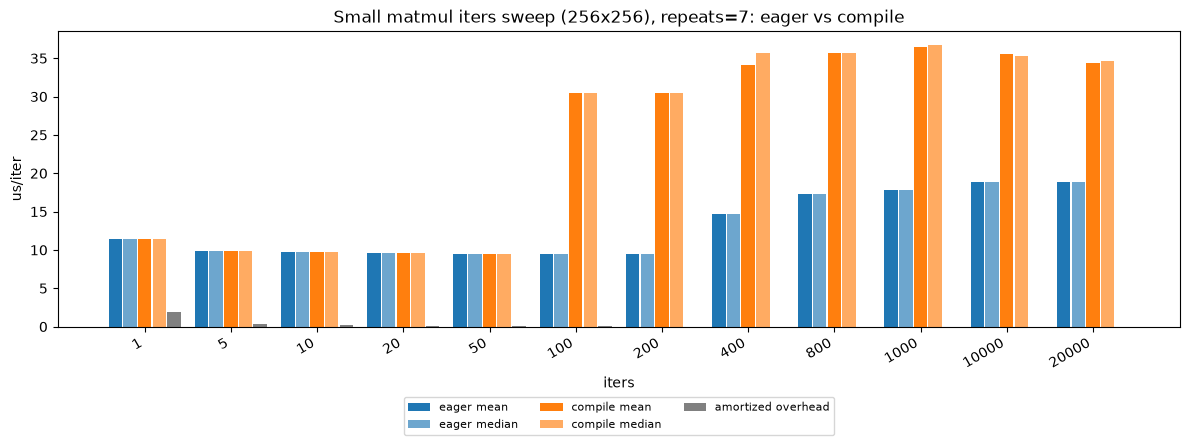

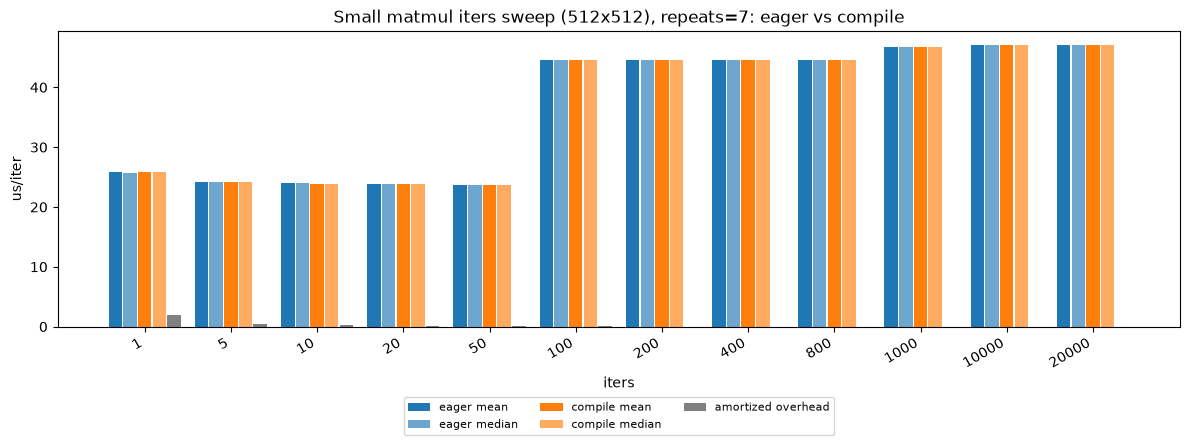

In [ ]:
import statistics

# Small matmul: sweep measured iters - eager vs compile on same graph (reuses bench)
if not torch.cuda.is_available():
    print("CUDA unavailable; skipping small matmul iters sweep")
else:
    compiled = None
    if not PROFILE_COMPILE:
        if VERBOSE:
            print("compile profiling disabled (PROFILE_COMPILE=False)")
    else:
        try:
            compiled = torch.compile(torch.matmul)
        except Exception as e:
            if VERBOSE:
                print(f"compile torch.matmul skipped ({type(e).__name__}: {e})")

    overhead_us = measurement_overhead_us()
    if VERBOSE:
        print(f"measurement overhead (empty CUDA events, {OH_TRIALS} trials): {overhead_us:.2f} us")

    def plot_iters_sweep(M, K, N, repeats):
        try:
            a = torch.randn(M, K, device="cuda")
            b = torch.randn(K, N, device="cuda")
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            print(f"skip {M}x{K} matmul iters sweep: OOM during alloc")
            return
        if compiled is not None:
            bench(compiled, a, b, warmup=COMPILE_WARMUP, iters=COMPILE_ITERS)  # JIT compile before compile sweep
        eager_mean, eager_med = [], []
        compile_mean, compile_med = [], []
        if VERBOSE:
            print(f"torch.matmul ({M}x{K}) @ ({K}x{N}), warmup={WARMUP}, repeats={repeats}")
        for n in ITERS_LIST:
            # WARMUP/iters here are measured-loop settings; COMPILE_* only primes compile above
            e_s = bench_us_samples(torch.matmul, a, b, warmup=WARMUP, iters=n, repeats=repeats)
            e_mean, e_med = statistics.mean(e_s), statistics.median(e_s)
            eager_mean.append(e_mean)
            eager_med.append(e_med)
            line = f"  iters={n:3d}: eager mean {e_mean:.2f} med {e_med:.2f} us/iter"
            if compiled is not None:
                c_s = bench_us_samples(compiled, a, b, warmup=WARMUP, iters=n, repeats=repeats)
                c_mean, c_med = statistics.mean(c_s), statistics.median(c_s)
                compile_mean.append(c_mean)
                compile_med.append(c_med)
                line += f", compile mean {c_mean:.2f} med {c_med:.2f} us/iter"
            if VERBOSE:
                print(line)

        amort_us = eager_mean[0] - eager_mean[-1]  # us/iter drops as fixed timing overhead is spread
        if VERBOSE:
            print(f"rough amortized (eager mean us/iter[n=1] - [n={ITERS_LIST[-1]}]): {amort_us:.2f} us")

        plot_iters_sweep_bars(
            ITERS_LIST,
            eager_mean,
            eager_med,
            compile_mean,
            compile_med,
            overhead_us,
            iters_sweep_plot_title("Small matmul", f"{M}x{K}", repeats),
        )

    for repeats in REPEATS:
        for sz in SWEEP_SIZES:
            plot_iters_sweep(sz, sz, sz, repeats)


## Softmax: iters sweep (bench)


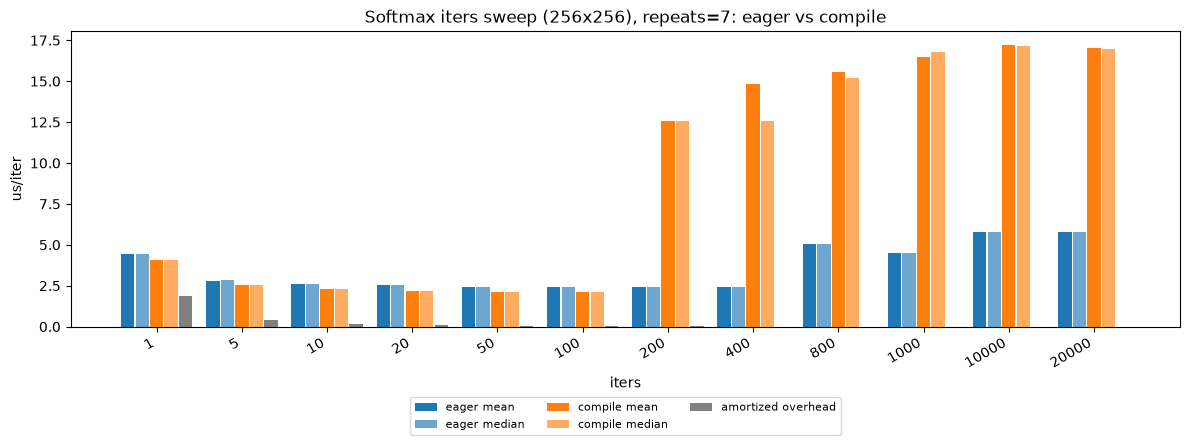

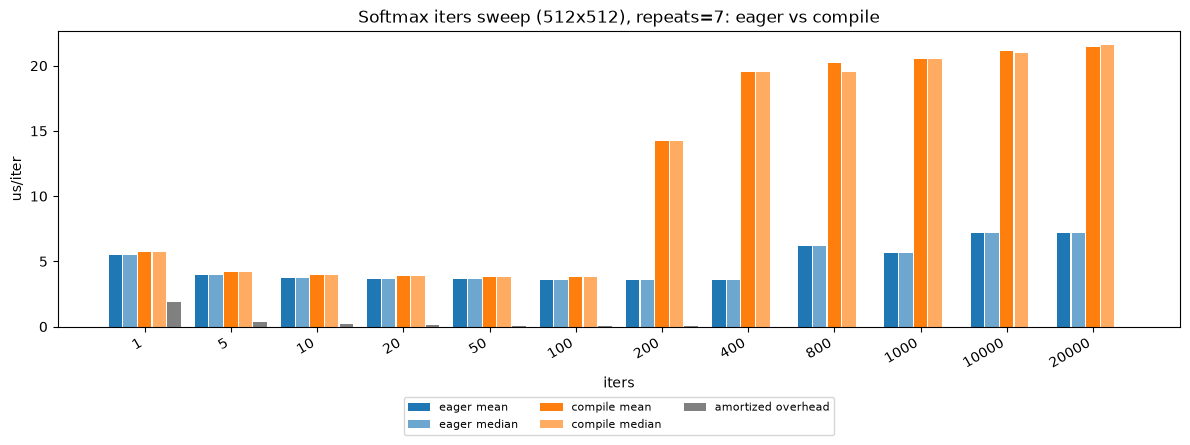

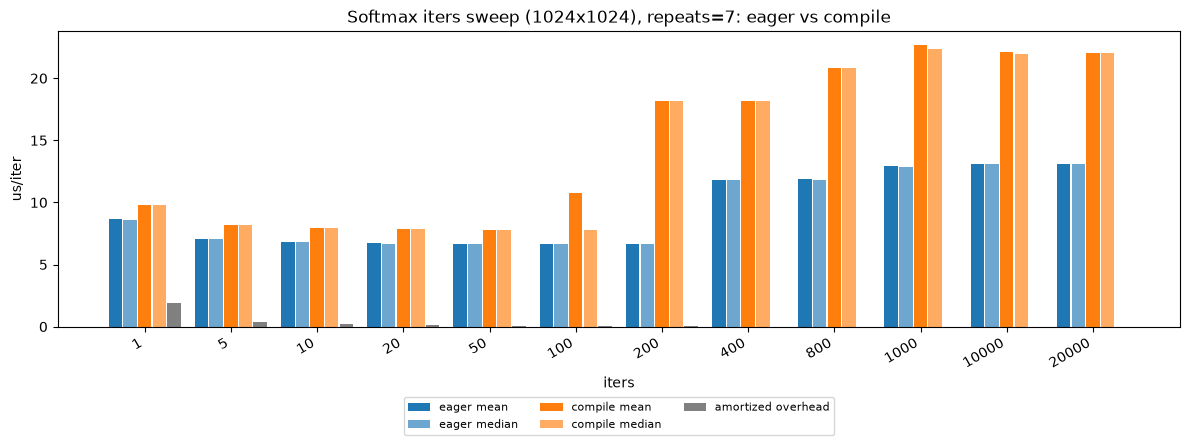

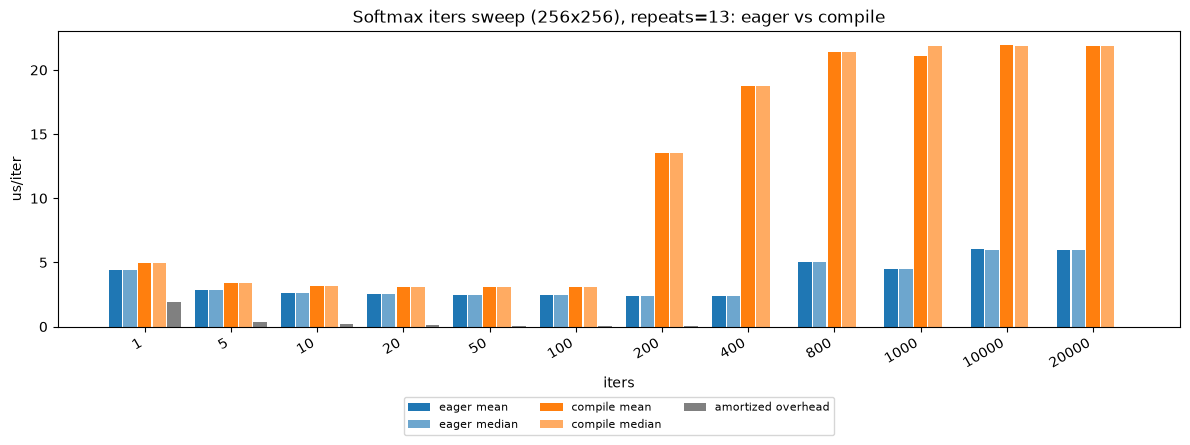

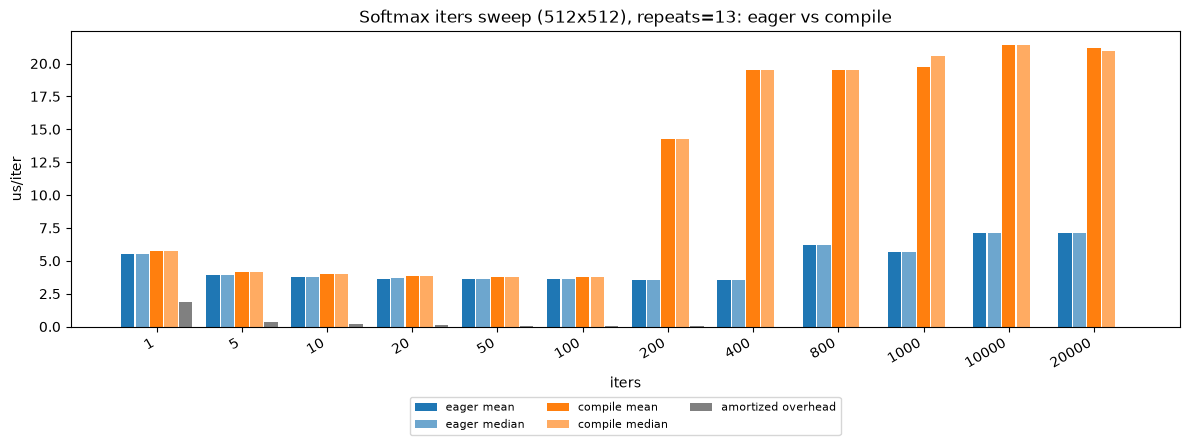

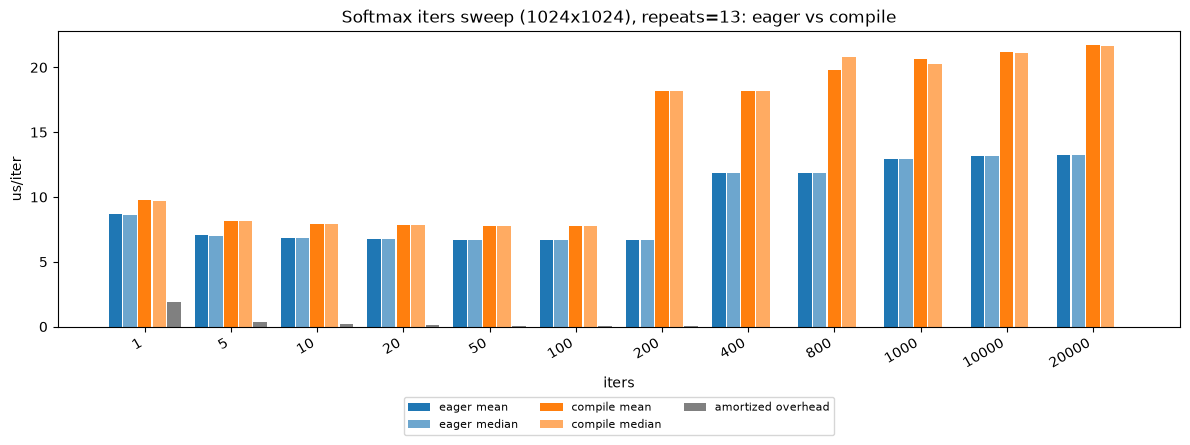

In [ ]:
import statistics

# Softmax: sweep measured iters - eager vs compile on same graph (reuses bench)
if not torch.cuda.is_available():
    print("CUDA unavailable; skipping softmax iters sweep")
else:
    def softmax_last(x):
        return torch.softmax(x, dim=-1)

    compiled = None
    if not PROFILE_COMPILE:
        if VERBOSE:
            print("compile profiling disabled (PROFILE_COMPILE=False)")
    else:
        try:
            compiled = torch.compile(softmax_last)
        except Exception as e:
            if VERBOSE:
                print(f"compile softmax skipped ({type(e).__name__}: {e})")

    overhead_us = measurement_overhead_us()
    if VERBOSE:
        print(f"measurement overhead (empty CUDA events, {OH_TRIALS} trials): {overhead_us:.2f} us")

    def plot_iters_sweep(sz, repeats):
        try:
            x = torch.randn(sz, sz, device="cuda")
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            print(f"skip {sz}x{sz} softmax iters sweep: OOM during alloc")
            return
        if compiled is not None:
            bench(compiled, x, warmup=COMPILE_WARMUP, iters=COMPILE_ITERS)  # JIT compile before compile sweep
        eager_mean, eager_med = [], []
        compile_mean, compile_med = [], []
        if VERBOSE:
            print(f"softmax ({sz}x{sz}), dim=-1, warmup={WARMUP}, repeats={repeats}")
        for n in ITERS_LIST:
            e_s = bench_us_samples(softmax_last, x, warmup=WARMUP, iters=n, repeats=repeats)
            e_mean, e_med = statistics.mean(e_s), statistics.median(e_s)
            eager_mean.append(e_mean)
            eager_med.append(e_med)
            line = f"  iters={n:3d}: eager mean {e_mean:.2f} med {e_med:.2f} us/iter"
            if compiled is not None:
                c_s = bench_us_samples(compiled, x, warmup=WARMUP, iters=n, repeats=repeats)
                c_mean, c_med = statistics.mean(c_s), statistics.median(c_s)
                compile_mean.append(c_mean)
                compile_med.append(c_med)
                line += f", compile mean {c_mean:.2f} med {c_med:.2f} us/iter"
            if VERBOSE:
                print(line)

        amort_us = eager_mean[0] - eager_mean[-1]  # us/iter drops as fixed timing overhead is spread
        if VERBOSE:
            print(f"rough amortized (eager mean us/iter[n=1] - [n={ITERS_LIST[-1]}]): {amort_us:.2f} us")

        plot_iters_sweep_bars(
            ITERS_LIST,
            eager_mean,
            eager_med,
            compile_mean,
            compile_med,
            overhead_us,
            iters_sweep_plot_title("Softmax", f"{sz}x{sz}", repeats),
        )

    for repeats in REPEATS:
        for sz in SWEEP_SIZES:
            plot_iters_sweep(sz, repeats)


## Norm: iters sweep (bench)


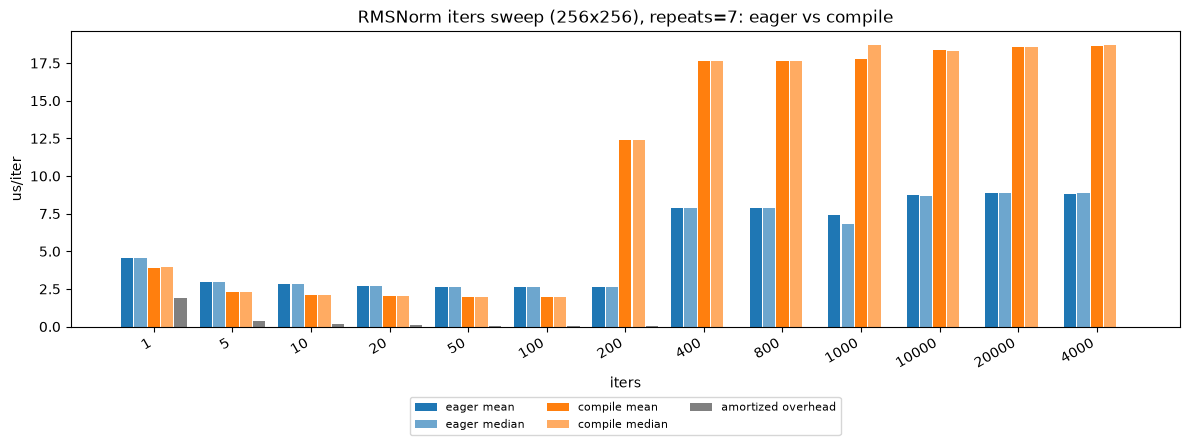

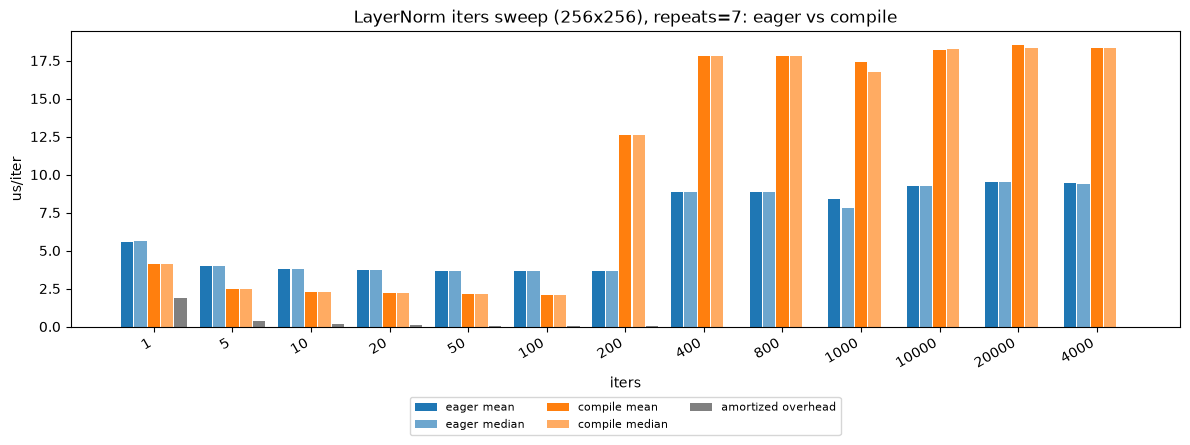

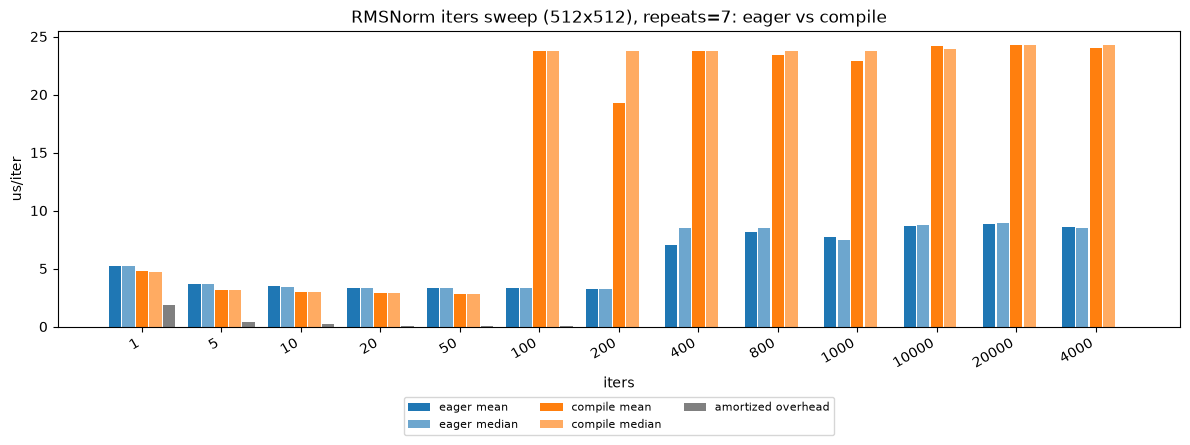

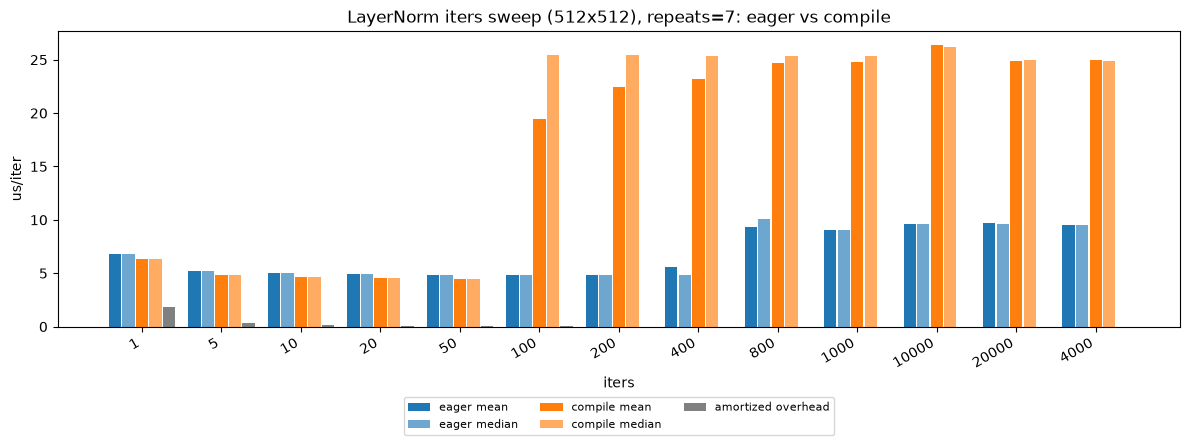

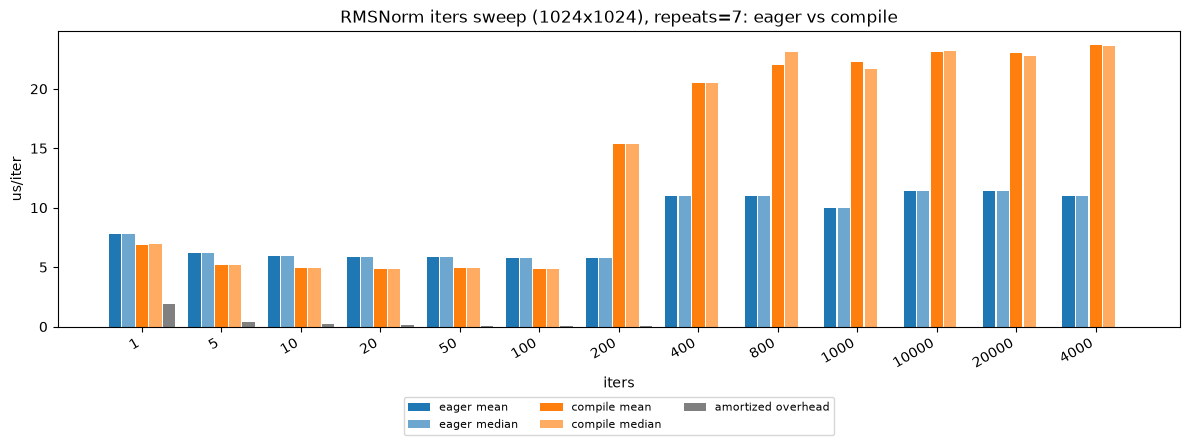

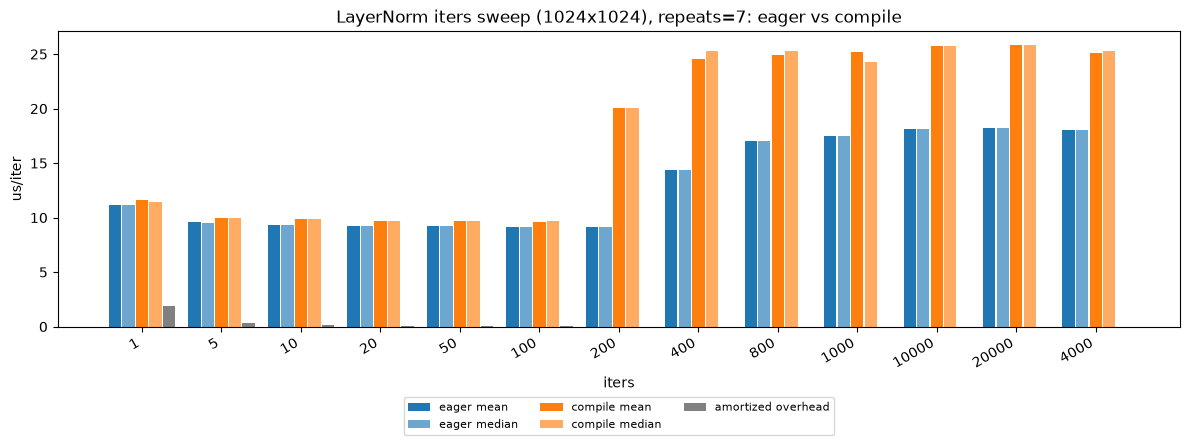

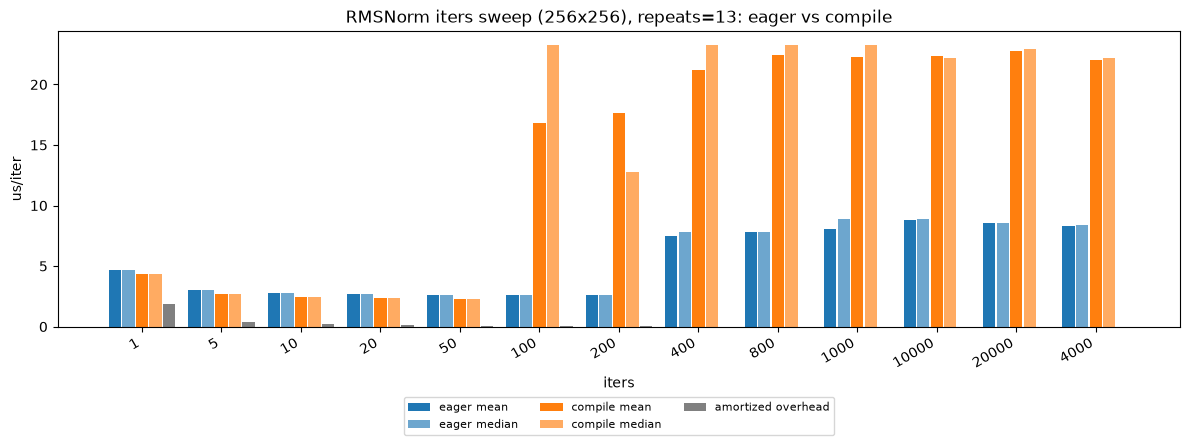

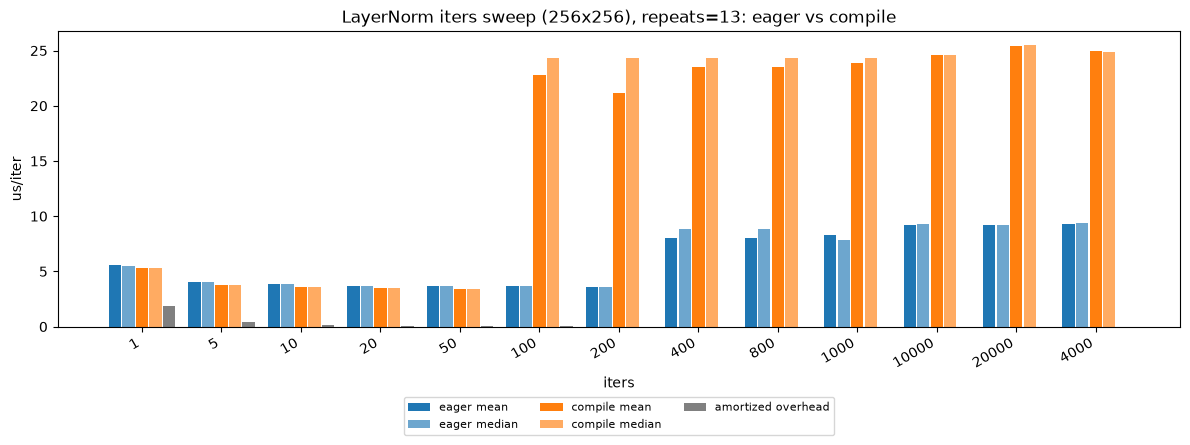

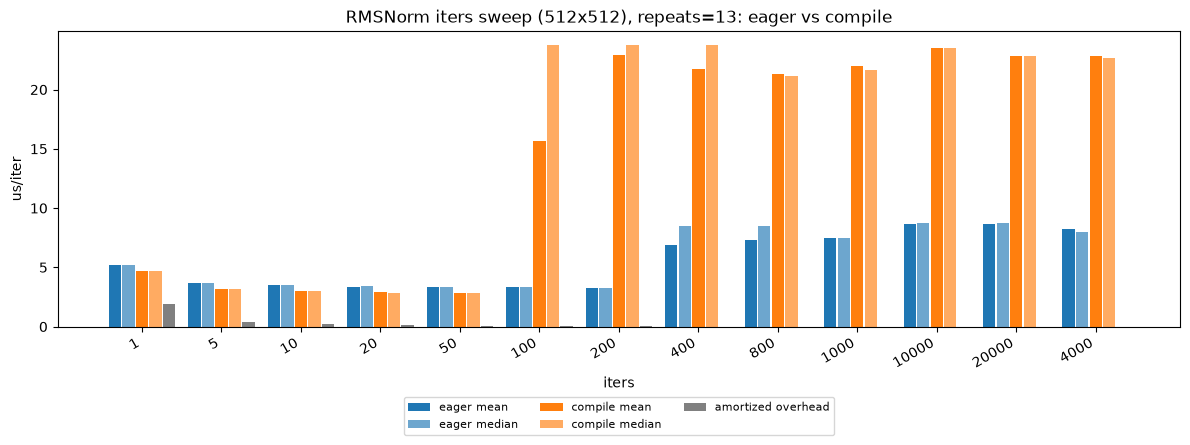

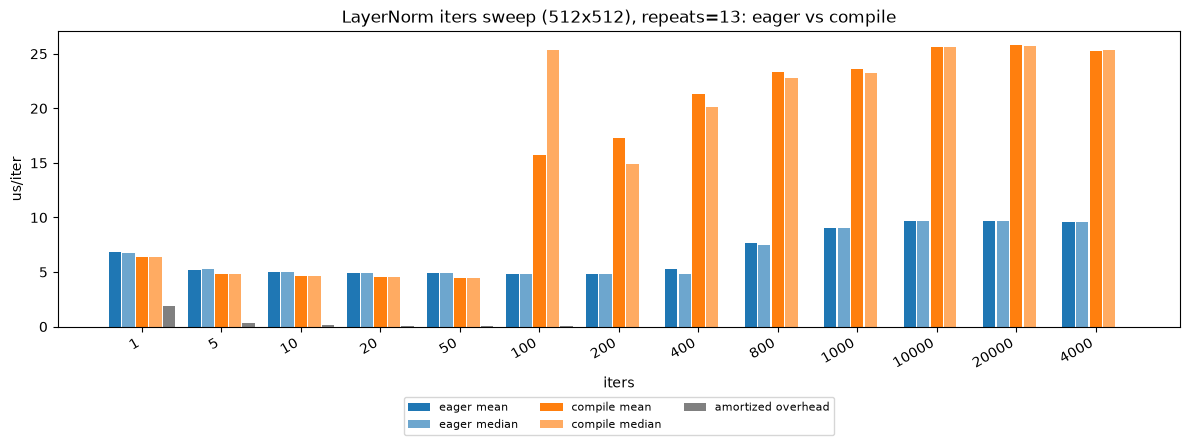

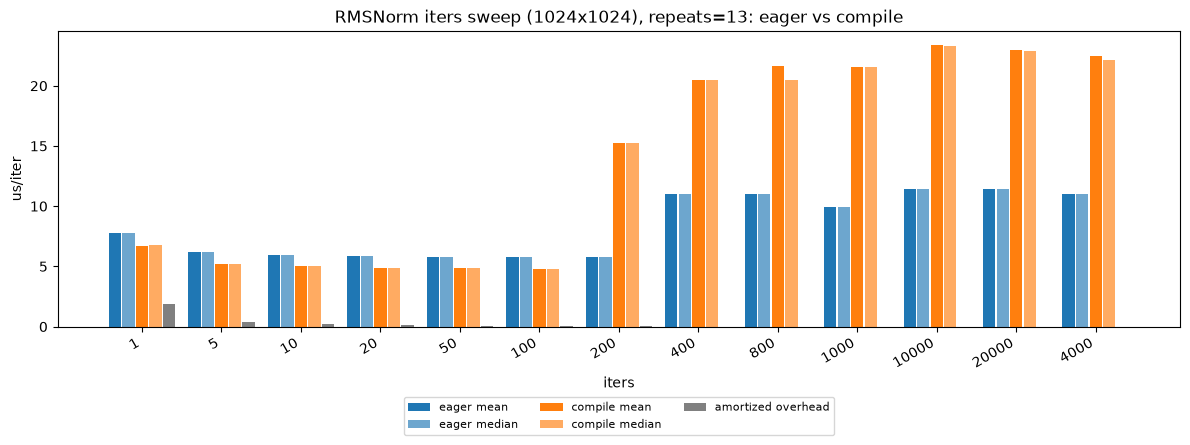

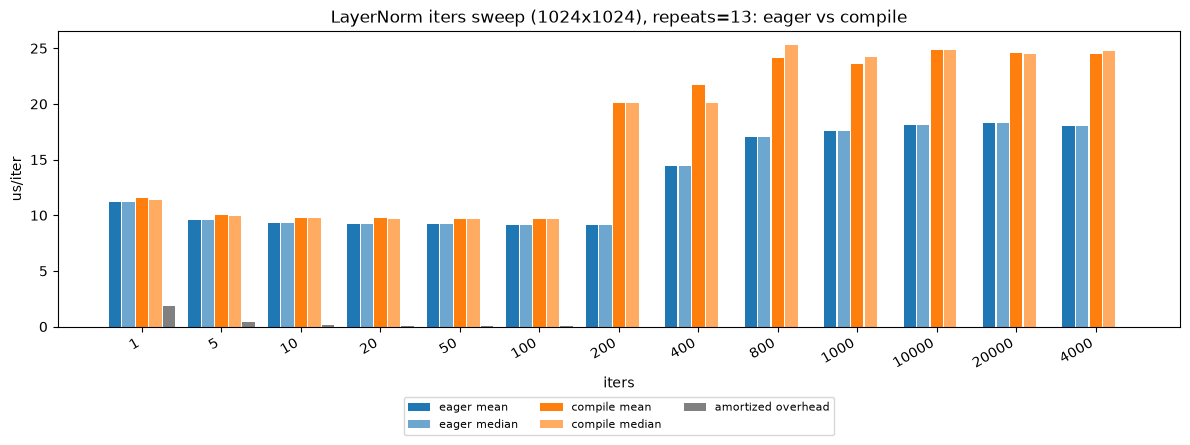

In [ ]:
import statistics
import torch.nn.functional as F

# Norm (RMSNorm / LayerNorm): sweep measured iters - eager vs compile (reuses bench)
if not torch.cuda.is_available():
    print("CUDA unavailable; skipping norm iters sweep")
else:
    def rms_norm_last(x):
        return F.rms_norm(x, (x.size(-1),))

    def layer_norm_last(x, weight, bias):
        return F.layer_norm(x, (x.size(-1),), weight, bias)

    compiled_rms = None
    compiled_ln = None
    if not PROFILE_COMPILE:
        if VERBOSE:
            print("compile profiling disabled (PROFILE_COMPILE=False)")
    else:
        try:
            compiled_rms = torch.compile(rms_norm_last)
        except Exception as e:
            if VERBOSE:
                print(f"compile rms_norm skipped ({type(e).__name__}: {e})")
        try:
            compiled_ln = torch.compile(layer_norm_last)
        except Exception as e:
            if VERBOSE:
                print(f"compile layer_norm skipped ({type(e).__name__}: {e})")

    overhead_us = measurement_overhead_us()
    if VERBOSE:
        print(f"measurement overhead (empty CUDA events, {OH_TRIALS} trials): {overhead_us:.2f} us")

    def plot_iters_sweep(sz, repeats, op_label, eager_fn, compiled_fn, bench_args):
        if compiled_fn is not None:
            bench(compiled_fn, *bench_args, warmup=COMPILE_WARMUP, iters=COMPILE_ITERS)  # JIT compile before compile sweep
        eager_mean, eager_med = [], []
        compile_mean, compile_med = [], []
        if VERBOSE:
            print(f"{op_label} ({sz}x{sz}), normalized dim=-1, warmup={WARMUP}, repeats={repeats}")
        for n in ITERS_LIST:
            e_s = bench_us_samples(eager_fn, *bench_args, warmup=WARMUP, iters=n, repeats=repeats)
            e_mean, e_med = statistics.mean(e_s), statistics.median(e_s)
            eager_mean.append(e_mean)
            eager_med.append(e_med)
            line = f"  iters={n:3d}: eager mean {e_mean:.2f} med {e_med:.2f} us/iter"
            if compiled_fn is not None:
                c_s = bench_us_samples(compiled_fn, *bench_args, warmup=WARMUP, iters=n, repeats=repeats)
                c_mean, c_med = statistics.mean(c_s), statistics.median(c_s)
                compile_mean.append(c_mean)
                compile_med.append(c_med)
                line += f", compile mean {c_mean:.2f} med {c_med:.2f} us/iter"
            if VERBOSE:
                print(line)

        amort_us = eager_mean[0] - eager_mean[-1]  # us/iter drops as fixed timing overhead is spread
        if VERBOSE:
            print(f"rough amortized (eager mean us/iter[n=1] - [n={ITERS_LIST[-1]}]): {amort_us:.2f} us")

        plot_iters_sweep_bars(
            ITERS_LIST,
            eager_mean,
            eager_med,
            compile_mean,
            compile_med,
            overhead_us,
            iters_sweep_plot_title(op_label, f"{sz}x{sz}", repeats),
        )

    norm_ops = (
        ("RMSNorm", rms_norm_last, compiled_rms),
        ("LayerNorm", layer_norm_last, compiled_ln),
    )

    for repeats in REPEATS:
        for sz in SWEEP_SIZES:
            try:
                x = torch.randn(sz, sz, device="cuda")
                weight = torch.ones(sz, device="cuda")
                bias = torch.zeros(sz, device="cuda")
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache()
                print(f"skip {sz}x{sz} norm iters sweep: OOM during alloc")
                continue
            for op_label, eager_fn, compiled_fn in norm_ops:
                if op_label == "RMSNorm":
                    bench_args = (x,)
                else:
                    bench_args = (x, weight, bias)
                plot_iters_sweep(sz, repeats, op_label, eager_fn, compiled_fn, bench_args)
